# Revision 2026-10-02 — Check Ia: does $\lambda_1/\sum\lambda$ under shuffled labels depend on $T$? (all blocks)

**Question.** With training labels that carry no concept (a random permutation), is the top-eigenvalue share of the AGOP after one RFM step, $s(1)$, the same as after $T>1$ steps? If $s_{\text{shuf}}(T)=s_{\text{shuf}}(1)$ for all $T$, the RFM iteration does not by itself concentrate the spectrum. If $s_{\text{shuf}}(T)$ grows with $T$, part of any reported $s\approx1$ is produced by the iteration and not by the concept.

**Relation to Check I.** Check I, Regime C traces $s(T)$ at each concept's *best* block with 10 permutations. This check covers **all 6 blocks**, all $(\sigma,\text{normalize})$ settings and $B=20$ permutations, and adds a formal test of $T$-invariance. Section 5 cross-checks against Check I's Regime C file (read-only).

**Object.** For a concept $c$ and block $\ell$, $Z_\ell\in\mathbb{R}^{n\times384}$ holds the cached last-token residual activations (train split), centred and optionally row-normalised by `_preprocess`. Start from $M_0=I_{384}$ and set $M_{t+1}=\mathrm{AGOP}(Z_\ell,y;M_t,\sigma,\lambda=10^{-3})$ using `rfm_guppy.rfm._agop_step`. The statistic is
$$s(T)=\frac{\lambda_1(M_T)}{\operatorname{tr}(M_T)}\in\big[\tfrac1{384},1\big],\qquad T=1,\dots,10.$$
A **cell** is a tuple $(c,\ell,\text{normalize},\sigma)$: $3\times6\times2\times3=108$ cells. In each cell, $s$ is computed for the real labels and for $B=20$ permutations $y^{\pi_b}$. The permutations are drawn once per concept, with seed `20261002`.

**Hypothesis $H_0$ (the "same result" claim).** Under shuffled labels, $s$ does not depend on $T$. For $T\ge2$, define the paired differences $\Delta_b(T)=s_b(T)-s_b(1)$, $b=1..B$.

**Falsification criterion (fixed before running).** $H_0$ is refuted at $(\text{cell},T)$ if
1. $|\operatorname{median}_b\Delta_b(T)|>0.05$ (a practically relevant change in the share), **and**
2. a two-sided sign test on $\{\Delta_b(T)\}_{b=1}^{B}$ gives $p<0.05$.

There are $108\times9=972$ $(\text{cell},T)$ pairs.

In [1]:
import sys, os, json, time
import numpy as np
import pandas as pd
from scipy.stats import binomtest
ROOT = os.path.abspath('..'); sys.path.insert(0, ROOT)
from rfm_guppy.rfm import _agop_step, _preprocess
CACHE = os.path.join(ROOT, 'rfm_guppy', 'cache')
CONCEPTS = ['food', 'valence', 'env_social']; NB = 6
SIGMAS = (1, 10, 100); NORMS = (False, True)
B, TMAX, LAM, SEED = 20, 10, 1e-3, 20261002
PREFIX = 'Ia-shuffle-label-on-blocks'
FORCE = True  # True: recompute the sweep even if the .npz cache exists (overwrites it)

X, Y, V = {}, {}, {}
for c in CONCEPTS:
    X[c] = np.load(f'{CACHE}/{c}_train_activations.npy').astype(np.float64)
    Y[c] = np.array([d['label'] for d in json.load(open(f'{CACHE}/concept_{c}.json'))['train']], float)
    V[c] = dict(np.load(f'{CACHE}/{c}_vectors.npz'))
    print(f'{c:10s} train {X[c].shape}  positives {int(Y[c].sum())}/{len(Y[c])}')

food       train (360, 6, 384)  positives 180/360
valence    train (120, 6, 384)  positives 60/120
env_social train (360, 6, 384)  positives 180/360


## 1. Sweep: $s(T)$, $T=1..10$, real and shuffled labels, all 108 cells
Row 0 of each array holds the real labels; rows $1..B$ hold the permutations. The result is cached to `Ia-shuffle-label-on-blocks_sT.npz` (≈12 min on a laptop CPU when not cached).

In [2]:
OUT = f'{PREFIX}_sT.npz'
if not FORCE and os.path.exists(OUT):
    S = dict(np.load(OUT)); print('loaded cached', OUT)
else:
    rng = np.random.default_rng(SEED); S = {}; t0 = time.time()
    for c in CONCEPTS:
        perms = [rng.permutation(len(Y[c])) for _ in range(B)]
        for l in range(NB):
            for nz in NORMS:
                Zc, _ = _preprocess(X[c][:, l, :], center=True, normalize=nz)
                for L in SIGMAS:
                    A = np.zeros((B + 1, TMAX))
                    for b in range(B + 1):
                        yy = Y[c] if b == 0 else Y[c][perms[b - 1]]
                        M = np.eye(Zc.shape[1])
                        for t in range(TMAX):
                            M, _, _ = _agop_step(Zc, yy, M, L, LAM)
                            ev = np.linalg.eigvalsh(M)
                            A[b, t] = ev[-1] / max(ev.sum(), 1e-12)
                    S[f'{c}|{l}|{int(nz)}|{L}'] = A
        print(c, f'{time.time() - t0:.0f}s')
    np.savez(OUT, **S)
print(len(S), 'cells')

food 254s


valence 1146s


env_social 1398s
108 cells


## 2. Reproduction gate
For each of the 18 (concept, block) pairs, the real-label value $s(T^\star)$ at the stored hyperparameters $(\sigma^\star,T^\star,\text{normalize}^\star)$ must match the cached `lam1_share` to within $10^{-4}$. Otherwise this sweep is not computing the statistic the paper reports.

In [3]:
for c in CONCEPTS:
    for l in range(NB):
        L, T, nz = int(V[c]['hp_L'][l]), int(V[c]['hp_T'][l]), int(V[c]['hp_normalize'][l])
        s = S[f'{c}|{l}|{nz}|{L}'][0, T - 1]
        assert abs(s - V[c]['lam1_share'][l]) < 1e-4, (c, l, s, V[c]['lam1_share'][l])
print('reproduction gate passed: 18/18 stored shares reproduced')

reproduction gate passed: 18/18 stored shares reproduced


## 3. Test of $H_0$: is $s_{\text{shuf}}(T)=s_{\text{shuf}}(1)$?

In [4]:
def sign_p(d):
    d = d[np.abs(d) > 1e-12]
    return 1.0 if len(d) == 0 else binomtest(int((d > 0).sum()), len(d)).pvalue

rows = []
for k, A in S.items():
    c, l, nz, L = k.split('|'); sh = A[1:]
    for T in range(2, TMAX + 1):
        d = sh[:, T - 1] - sh[:, 0]; med = float(np.median(d)); p = sign_p(d)
        rows.append(dict(concept=c, block=int(l), normalize=int(nz), sigma=int(L), T=T,
                         median_delta=med, n_pos=int((d > 0).sum()), sign_p=p,
                         refuted=bool(abs(med) > 0.05 and p < 0.05)))
H = pd.DataFrame(rows); H.to_csv(f'{PREFIX}_H0_tests.csv', index=False)
print(f"H0 refuted in {H.refuted.sum()}/{len(H)} (cell, T) pairs")
print(f"median Δ over all pairs: min {H.median_delta.min():+.3f}, max {H.median_delta.max():+.3f}")
print(f"pairs with fewer than B/B increasing: {(H.n_pos < B).sum()}")
print('\nfirst T at which H0 is refuted, distribution over cells:')
print(H[H.refuted].groupby(['concept', 'block', 'normalize', 'sigma']).T.min().value_counts().sort_index())

H0 refuted in 972/972 (cell, T) pairs
median Δ over all pairs: min +0.149, max +0.587
pairs with fewer than B/B increasing: 5

first T at which H0 is refuted, distribution over cells:
T
2    108
Name: count, dtype: int64


### 3b. Per-cell summary (real vs shuffled, $T=1$ vs $T=10$)

In [5]:
summ = []
for k, A in S.items():
    c, l, nz, L = k.split('|'); sh = A[1:]
    summ.append(dict(concept=c, block=int(l), normalize=int(nz), sigma=int(L),
                     real_s1=A[0, 0], real_s10=A[0, -1],
                     shuf_med_s1=np.median(sh[:, 0]), shuf_med_s10=np.median(sh[:, -1]),
                     shuf_max_s10=sh[:, -1].max(), median_delta10=np.median(sh[:, -1] - sh[:, 0])))
P = pd.DataFrame(summ); P.to_csv(f'{PREFIX}_per_cell.csv', index=False)
pd.set_option('display.width', 200); pd.set_option('display.max_rows', 200)
print(P.round(3).to_string(index=False))

   concept  block  normalize  sigma  real_s1  real_s10  shuf_med_s1  shuf_med_s10  shuf_max_s10  median_delta10
      food      0          0      1    0.376     0.851        0.165         0.553         0.775           0.389
      food      0          0     10    0.412     0.880        0.181         0.582         0.697           0.395
      food      0          0    100    0.412     0.941        0.199         0.613         0.760           0.434
      food      0          1      1    0.251     0.790        0.176         0.594         0.776           0.427
      food      0          1     10    0.310     0.720        0.205         0.597         0.862           0.396
      food      0          1    100    0.315     0.855        0.216         0.661         0.844           0.428
      food      1          0      1    0.161     1.000        0.198         0.578         0.821           0.387
      food      1          0     10    0.473     1.000        0.313         0.678         0.857         

## 4. The cells the paper reports (stored hyperparameters)
At $(\sigma^\star,T^\star,\text{normalize}^\star)$, the real value $s_{\text{real}}(T^\star)$ is compared with the shuffled distribution at the **same** $T^\star$, and with $s_{\text{real}}(1)$ against the shuffled values at $T=1$. Here $p_{\text{perm}}=(1+\#\{s_{\text{shuf}}\ge s_{\text{real}}\})/(1+B)$, whose smallest possible value with $B=20$ is $1/21\approx0.048$. Hyperparameters are frozen (not re-selected on shuffled labels; that is Check I, Regime B).

In [6]:
rows = []
for c in CONCEPTS:
    for l in range(NB):
        L, T, nz = int(V[c]['hp_L'][l]), int(V[c]['hp_T'][l]), int(V[c]['hp_normalize'][l])
        A = S[f'{c}|{l}|{nz}|{L}']; sh = A[1:]
        rows.append(dict(concept=c, block=l, sigma=L, normalize=nz, T_star=T,
                         real_sT=A[0, T - 1], shuf_med_sT=np.median(sh[:, T - 1]),
                         shuf_min_sT=sh[:, T - 1].min(), shuf_max_sT=sh[:, T - 1].max(),
                         p_perm_T=(1 + (sh[:, T - 1] >= A[0, T - 1]).sum()) / (1 + B),
                         real_s1=A[0, 0], shuf_med_s1=np.median(sh[:, 0]),
                         p_perm_1=(1 + (sh[:, 0] >= A[0, 0]).sum()) / (1 + B)))
R = pd.DataFrame(rows); R.to_csv(f'{PREFIX}_stored_hp.csv', index=False)
print(R.round(3).to_string(index=False))
print('\ncells with p_perm at T* >= 0.05 (reported share not distinguishable from shuffled):')
print(R[R.p_perm_T >= 0.05][['concept', 'block', 'T_star', 'real_sT', 'shuf_med_sT', 'p_perm_T']].round(3).to_string(index=False))
print(f"\nmax shuffled s over all 108 cells and all T: {max(A[1:].max() for A in S.values()):.4f}")
print(f"real s reaching >= 0.999 at some T: {sum((A[0] >= 0.999).any() for A in S.values())}/108 cells")

   concept  block  sigma  normalize  T_star  real_sT  shuf_med_sT  shuf_min_sT  shuf_max_sT  p_perm_T  real_s1  shuf_med_s1  p_perm_1
      food      0     10          0       3    0.761        0.480        0.371        0.544     0.048    0.412        0.181     0.048
      food      1      1          1       3    0.979        0.627        0.469        0.699     0.048    0.304        0.261     0.048
      food      2      1          1       8    1.000        0.606        0.470        0.867     0.048    0.272        0.241     0.095
      food      3      1          1       2    0.886        0.526        0.303        0.651     0.048    0.234        0.219     0.333
      food      4      1          1       2    0.884        0.472        0.371        0.600     0.048    0.232        0.212     0.286
      food      5      1          1       8    1.000        0.557        0.386        0.701     0.048    0.244        0.231     0.429
   valence      0     10          0      10    0.797        0.

## 5. Figure: $s(T)$ real vs shuffled band, every block at its stored $(\sigma^\star,\text{normalize}^\star)$

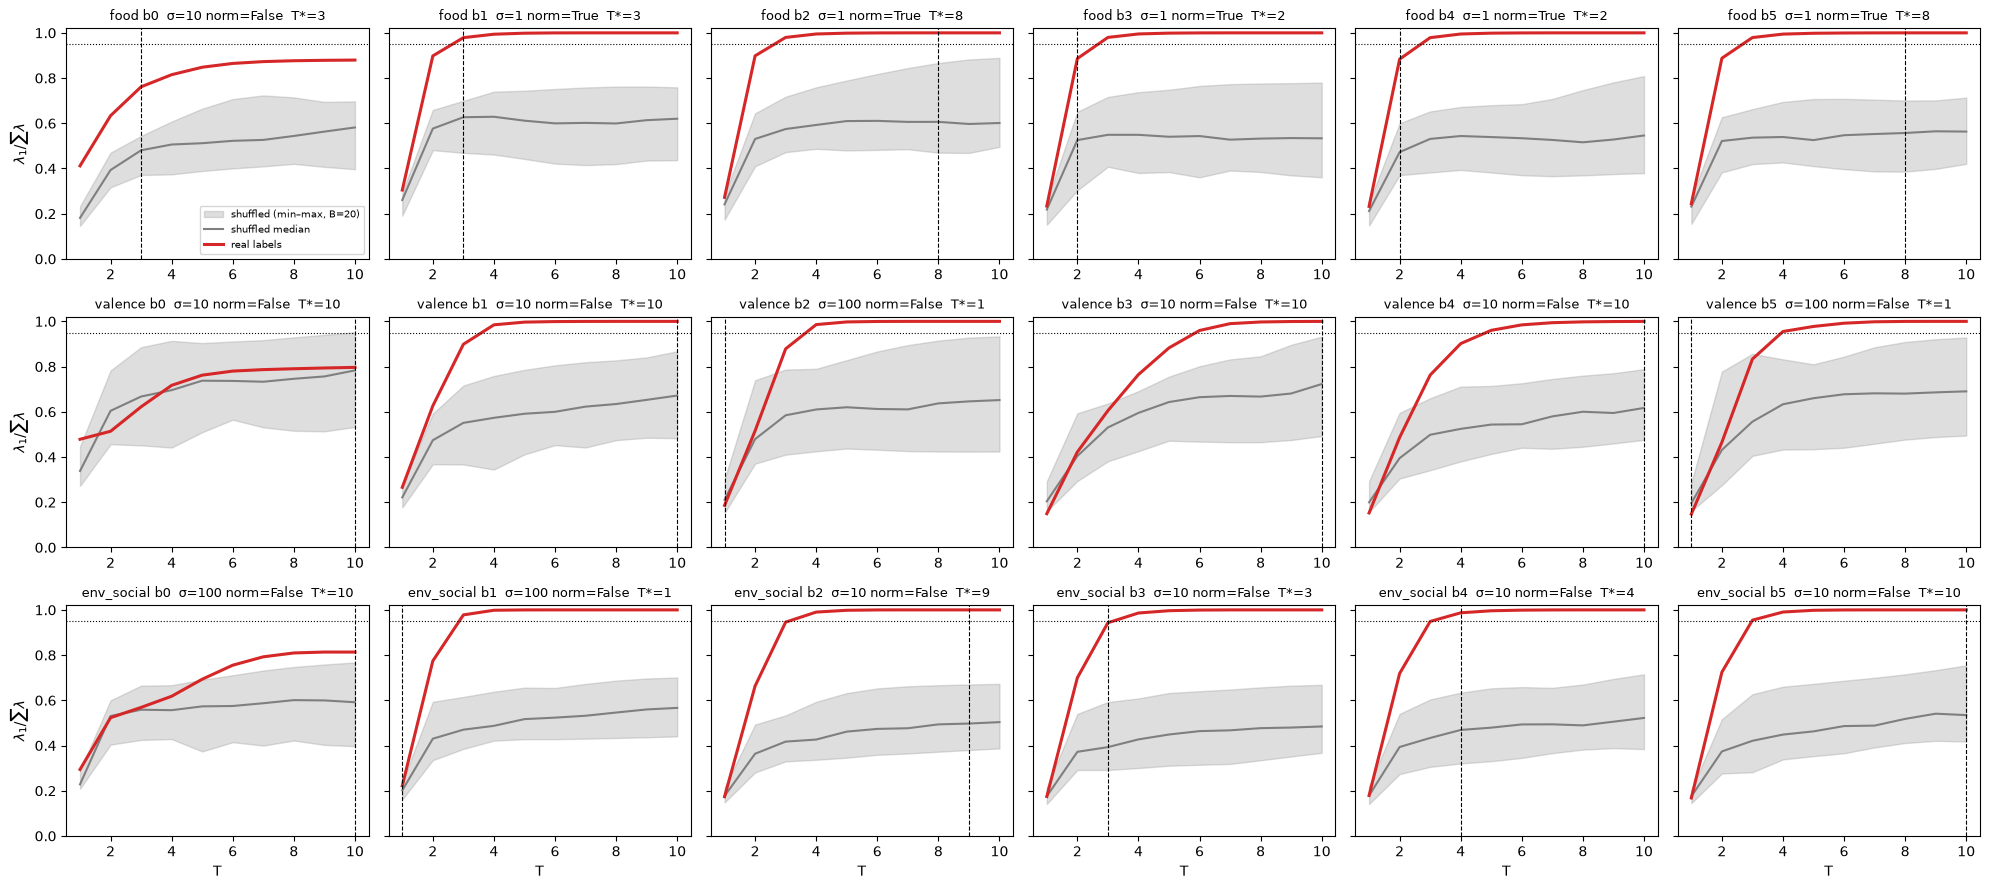

In [7]:
import matplotlib.pyplot as plt
Ts = np.arange(1, TMAX + 1)
fig, axs = plt.subplots(3, NB, figsize=(20, 9), sharey=True)
for i, c in enumerate(CONCEPTS):
    for l in range(NB):
        L, T, nz = int(V[c]['hp_L'][l]), int(V[c]['hp_T'][l]), int(V[c]['hp_normalize'][l])
        A = S[f'{c}|{l}|{nz}|{L}']; sh = A[1:]; ax = axs[i, l]
        ax.fill_between(Ts, sh.min(0), sh.max(0), color='tab:gray', alpha=.25, label=f'shuffled (min–max, B={B})')
        ax.plot(Ts, np.median(sh, 0), color='tab:gray', lw=1.5, label='shuffled median')
        ax.plot(Ts, A[0], color='tab:red', lw=2.2, label='real labels')
        ax.axvline(T, ls='--', color='k', lw=.8); ax.axhline(.95, ls=':', color='k', lw=.8)
        ax.set_title(f'{c} b{l}  σ={L} norm={bool(nz)}  T*={T}', fontsize=9); ax.set_ylim(0, 1.02)
        if i == 2: ax.set_xlabel('T')
    axs[i, 0].set_ylabel(r'$\lambda_1/\sum\lambda$')
axs[0, 0].legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.savefig(f'{PREFIX}_share_vs_T.png', dpi=130); plt.show()

## 6. Cross-check against Check I, Regime C (read-only)
Check I traced $s(T)$ at each concept's best block (argmax val $|\rho|$) with 10 permutations drawn from a different seed. The real-label curves are deterministic and must agree exactly. The shuffled medians should agree up to Monte-Carlo noise.

In [8]:
FC = 'I-shuffled-label-control_resultsC.npz'
if os.path.exists(FC):
    C = dict(np.load(FC))
    for c in CONCEPTS:
        b = int(np.argmax(V[c]['val_abs_rho']))
        for nz in (0, 1):
            for L in SIGMAS:
                mine = S[f'{c}|{b}|{nz}|{L}']; theirs_r = C[f'{c}_{nz}_{L}_real']; theirs_s = C[f'{c}_{nz}_{L}_shuf']
                print(f'{c:10s} b{b} nz={nz} σ={L:3d} | max|real diff| {np.abs(mine[0] - theirs_r).max():.1e} | '
                      f'shuf median s(10): Ia {np.median(mine[1:, -1]):.3f}  I {np.median(theirs_s[:, -1]):.3f}')
else:
    print('Check I Regime C file not found; skipped')

food       b3 nz=0 σ=  1 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.551  I 0.610
food       b3 nz=0 σ= 10 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.644  I 0.584
food       b3 nz=0 σ=100 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.753  I 0.795
food       b3 nz=1 σ=  1 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.534  I 0.618
food       b3 nz=1 σ= 10 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.640  I 0.614
food       b3 nz=1 σ=100 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.683  I 0.544
valence    b4 nz=0 σ=  1 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.640  I 0.589
valence    b4 nz=0 σ= 10 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.617  I 0.700
valence    b4 nz=0 σ=100 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.715  I 0.758
valence    b4 nz=1 σ=  1 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.650  I 0.562
valence    b4 nz=1 σ= 10 | max|real diff| 0.0e+00 | shuf median s(10): Ia 0.648  I 0.695
valence    b4 nz=1 σ=